# Phase 3 · Products: what sells the most and the least

**Business question 1:** Which products and categories sell the most and the least?

In this notebook we rank products and categories by revenue and by units, measure how concentrated revenue is (Pareto analysis) and classify every product as A, B or C. We also look at which categories gained or lost relevance between 2017 and 2018. The notebook closes with the answer to the business question.

**Input:** the SQLite database `olist.db` created in Phase 1. The queries are in the `sql/` folder.

**Outputs** in `data/processed/`:

| File | One row per | Used in |
|---|---|---|
| `product_abc.csv` | product | dashboard (Products page) |
| `category_summary.csv` | category | dashboard (Products page) |
| `category_monthly.csv` | category and month | forecast (Phase 4) and dashboard |

Olist does not publish product names, only an anonymous identifier, so we describe products by their category and price. All amounts are in Brazilian reais (R$) and exclude freight.

## 1. Libraries, paths, chart style and SQL helper

Same style and SQL helper as Phase 2. We add two color sets: a single blue hue from dark to light for the A, B and C classes, because the classes have an order, and a blue/red pair for categories that gain or lose share.

In [1]:
import sqlite3
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import MultipleLocator

PROCESSED = Path("..") / "data" / "processed"
DATABASE = PROCESSED / "olist.db"
SQL_DIR = Path("..") / "sql"
FIGURES = Path("..") / "reports" / "figures"
pd.set_option("display.max_columns", 40)

BLUE = "#2a78d6"
GRAY = "#898781"
LIGHT_GRAY = "#c3c2b7"
INK = "#0b0b0b"
SECONDARY_INK = "#52514e"
GRID = "#e1e0d9"
ABC_COLORS = {"A": "#184f95", "B": "#3987e5", "C": "#86b6ef"}
GAIN, LOSS = "#2a78d6", "#e34948"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.edgecolor": LIGHT_GRAY,
    "axes.labelcolor": SECONDARY_INK,
    "axes.titlecolor": INK,
    "axes.titlelocation": "left",
    "axes.titlesize": 12,
    "axes.titlepad": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": SECONDARY_INK,
    "ytick.color": SECONDARY_INK,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.frameon": False,
})

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]


def run_sql(name, show=True, parse_dates=None, **params):
    # Reads sql/<name>.sql, prints it and returns the result as a DataFrame
    query = (SQL_DIR / f"{name}.sql").read_text(encoding="utf-8")
    if show:
        print(query)
    with closing(sqlite3.connect(DATABASE)) as connection:
        return pd.read_sql_query(query, connection, params=params, parse_dates=parse_dates)

## 2. Analysis period

We use the same period as Phase 2, January 2017 to August 2018. Rankings and shares are computed with all the units sold in that period. The last complete day of data, August 21, 2018, is only needed later to define which products stopped selling.

In [2]:
PERIOD = {"start": "2017-01-01", "end": "2018-09-01"}
LAST_COMPLETE_DAY = pd.Timestamp("2018-08-21")

## 3. Categories: ranking by revenue and by units

For each category the query computes revenue, units, number of different products and average price, and ranks it twice: by revenue and by units. The cumulative share of revenue, computed with a window function, tells us how many categories are needed to reach a given share of the total.

In [3]:
categories = run_sql("category_ranking", **PERIOD).set_index("category")

needed_for_80 = (categories["cumulative_pct"].shift(fill_value=0) < 80).sum()
print(f"Categories needed to reach 80% of revenue: {needed_for_80} of {len(categories)}")
categories.head(10).round(1)

-- Categories ranked by revenue and by units, with each category's share and cumulative share of revenue
WITH category_sales AS (
    SELECT
        category,
        SUM(price) AS revenue,
        COUNT(*) AS units,
        COUNT(DISTINCT product_id) AS products,
        AVG(price) AS avg_price
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
    GROUP BY category
)
SELECT
    category,
    revenue,
    units,
    products,
    avg_price,
    100.0 * revenue / SUM(revenue) OVER () AS revenue_pct,
    100.0 * SUM(revenue) OVER (ORDER BY revenue DESC ROWS UNBOUNDED PRECEDING)
        / SUM(revenue) OVER () AS cumulative_pct,
    RANK() OVER (ORDER BY revenue DESC) AS rank_by_revenue,
    RANK() OVER (ORDER BY units DESC) AS rank_by_units
FROM category_sales
ORDER BY revenue DESC;



Categories needed to reach 80% of revenue: 18 of 74


,revenue,units,products,avg_price,revenue_pct,cumulative_pct,rank_by_revenue,rank_by_units
category,,,,,,,,
Health beauty,1229557.5,9422,2380,130.5,9.3,9.3,1,2
Watches gifts,1163187.9,5853,1297,198.7,8.8,18.2,2,7
Bed bath table,1022955.8,10945,2987,93.5,7.8,25.9,3,1
Sports leisure,952661.4,8413,2811,113.2,7.2,33.1,4,3
Computers accessories,887944.6,7631,1597,116.4,6.7,39.9,5,5
Furniture decor,706237.2,8095,2559,87.2,5.4,45.2,6,4
Housewares,614341.6,6783,2281,90.6,4.7,49.9,7,6
Cool stuff,609158.0,3711,767,164.1,4.6,54.5,8,12
Auto,577721.1,4131,1847,139.9,4.4,58.9,9,10


And the ten categories with the least revenue:

In [4]:
categories.tail(10).round(2)

,revenue,units,products,avg_price,revenue_pct,cumulative_pct,rank_by_revenue,rank_by_units
category,,,,,,,,
Fashion sport,2094.52,29,19,72.22,0.02,99.92,65,67
La cuisine,2054.99,14,10,146.78,0.02,99.94,66,69
Arts and craftmanship,1814.01,24,19,75.58,0.01,99.95,67,68
Diapers and hygiene,1365.89,36,10,37.94,0.01,99.96,68,64
Gaming computers,1306.95,8,2,163.37,0.01,99.97,69,72
Flowers,1110.04,33,14,33.64,0.01,99.98,70,65
Home comfort 2,760.27,30,5,25.34,0.01,99.99,71,66
Cds dvds musicals,730.00,14,1,52.14,0.01,99.99,72,69
Fashion childrens clothes,519.95,7,4,74.28,0.00,100.00,73,73


18 of the 74 categories (24%) bring in 80% of revenue. At category level the concentration is milder than the classic 80/20, because each category groups products with very different sales. The leaders are Health beauty (9.3%), Watches gifts (8.8%) and Bed bath table (7.8%).

At the other end, the last ten categories add up to less than 0.1% of revenue. Some are very small niches, such as Security and services, with 2 units sold in 20 months.

## 4. Pareto analysis of products

The Pareto principle, or 80/20 rule, says that a small share of the causes usually explains most of the effect. We test it with products: we sort them from the highest to the lowest revenue and measure what share of the products is needed to reach each share of revenue.

The query does the heavy lifting. It adds up each product's sales, sorts the products by revenue and computes the cumulative share with a window function. It also assigns the ABC class, which we explain in the next section.

In [5]:
products = run_sql("product_abc", parse_dates=["first_sale", "last_sale"], **PERIOD).set_index("product_id")
products["share_of_products_pct"] = np.arange(1, len(products) + 1) / len(products) * 100
print(f"Products sold in the period: {len(products):,}")

-- ABC classification of products by revenue.
-- A product's class depends on the cumulative share of revenue *before* it:
-- class A up to 80%, class B up to 95%, class C for the rest.
-- Ties in revenue are broken by product_id so the result is always the same.
WITH product_sales AS (
    SELECT
        product_id,
        MIN(category) AS category,
        COUNT(*) AS units,
        COUNT(DISTINCT order_id) AS orders,
        SUM(price) AS revenue,
        AVG(price) AS avg_price,
        MIN(purchase_date) AS first_sale,
        MAX(purchase_date) AS last_sale
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
    GROUP BY product_id
),
cumulative AS (
    SELECT
        *,
        100.0 * revenue / SUM(revenue) OVER () AS revenue_pct,
        100.0 * SUM(revenue) OVER (ORDER BY revenue DESC, product_id ROWS UNBOUNDED PRECEDING)
            / SUM(revenue) OVER () AS cumulative_pct
    FROM product_sales
)
SELECT
    *,
    CASE
        WHEN cumulative_p

Products sold in the period: 32,079


In [6]:
def products_needed(target_pct):
    count = (products["cumulative_pct"] - products["revenue_pct"] < target_pct).sum()
    return count, count / len(products) * 100


pd.DataFrame(
    [products_needed(target) for target in (50, 80, 95)],
    index=["50% of revenue", "80% of revenue", "95% of revenue"],
    columns=["products", "share_of_products_pct"],
).round(1)

,products,share_of_products_pct
50% of revenue,1810,5.6
80% of revenue,8309,25.9
95% of revenue,19324,60.2


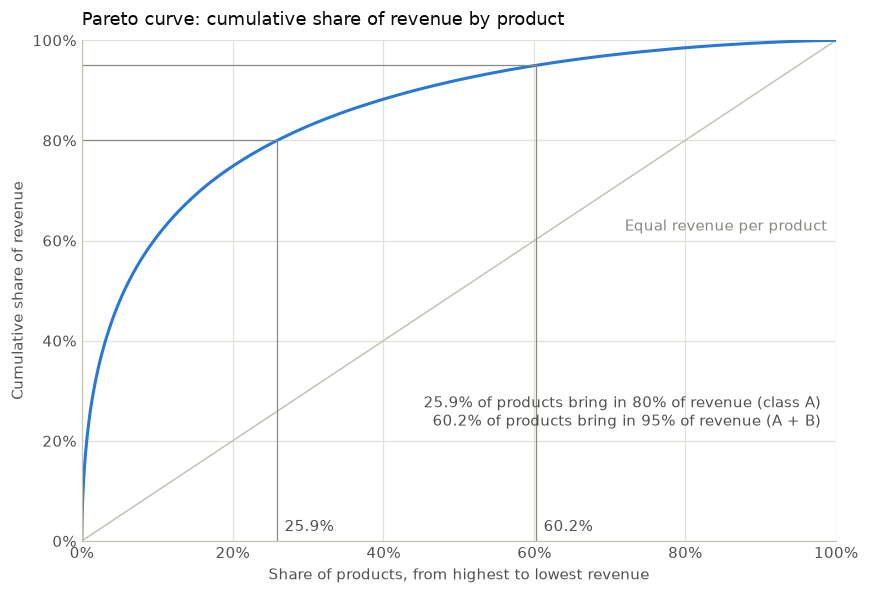

In [7]:
count_80, share_80 = products_needed(80)
count_95, share_95 = products_needed(95)

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot([0, 100], [0, 100], color=LIGHT_GRAY, linewidth=1)
ax.text(72, 62, "Equal revenue per product", color=GRAY)
ax.plot(products["share_of_products_pct"], products["cumulative_pct"], color=BLUE, linewidth=2)

# Guide lines at the class boundaries
for share, target in [(share_80, 80), (share_95, 95)]:
    ax.plot([share, share], [0, target], color=GRAY, linewidth=0.8)
    ax.plot([0, share], [target, target], color=GRAY, linewidth=0.8)
    ax.text(share + 1, 2, f"{share:.1f}%", color=SECONDARY_INK)

ax.text(
    98, 22,
    f"{share_80:.1f}% of products bring in 80% of revenue (class A)\n"
    f"{share_95:.1f}% of products bring in 95% of revenue (A + B)",
    ha="right", va="bottom", color=SECONDARY_INK,
)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_title("Pareto curve: cumulative share of revenue by product")
ax.set_xlabel("Share of products, from highest to lowest revenue")
ax.set_ylabel("Cumulative share of revenue")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
fig.tight_layout()
fig.savefig(FIGURES / "03_pareto_curve.png", dpi=150, bbox_inches="tight")
plt.show()

The Pareto principle holds almost exactly: 25.9% of the products (8,309 of 32,079) bring in 80% of revenue. The concentration is even stronger at the top, where just 5.6% of the products bring in half of the revenue. The last 40% of the products, on the other hand, add up to only 5%.

The gray diagonal shows what the curve would look like if every product brought in the same revenue. The farther the blue curve is from the diagonal, the more concentrated sales are.

## 5. ABC classification

The ABC classification turns the Pareto curve into three groups that are easy to act on:

| Class | Rule | Meaning |
|---|---|---|
| A | products that make up the first 80% of revenue | star products |
| B | the next 15%, up to 95% | mid-range products |
| C | the last 5% | products that bring in almost nothing |

In the query, a `CASE` expression assigns the class according to the cumulative revenue *before* each product, so the product that crosses the 80% line still counts as A. Ties in revenue are broken by `product_id`, so the classification is always the same.

In [8]:
abc = products.groupby("abc_class").agg(
    products=("units", "size"),
    units=("units", "sum"),
    revenue=("revenue", "sum"),
    median_price=("avg_price", "median"),
    median_units=("units", "median"),
)
abc["products_pct"] = abc["products"] / abc["products"].sum() * 100
abc["units_pct"] = abc["units"] / abc["units"].sum() * 100
abc["revenue_pct"] = abc["revenue"] / abc["revenue"].sum() * 100
abc.round(1)

,products,units,revenue,median_price,median_units,products_pct,units_pct,revenue_pct
abc_class,,,,,,,,
A,8309,68885,10543831.5,188.8,4.0,25.9,62.7,80.0
B,11015,23944,1977012.3,115.0,1.0,34.3,21.8,15.0
C,12755,17043,658934.2,39.9,1.0,39.8,15.5,5.0


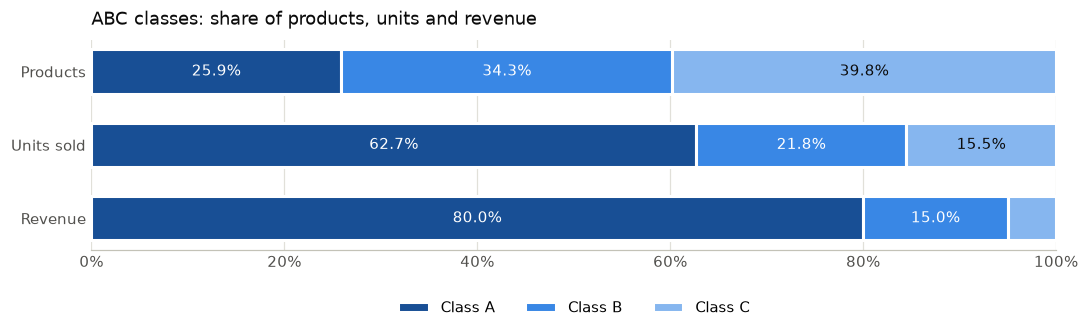

In [9]:
shares = abc[["products_pct", "units_pct", "revenue_pct"]].T
shares.index = ["Products", "Units sold", "Revenue"]

fig, ax = plt.subplots(figsize=(10, 3.4))
left = np.zeros(len(shares))
for abc_class in ["A", "B", "C"]:
    widths = shares[abc_class].to_numpy()
    ax.barh(shares.index, widths, left=left, color=ABC_COLORS[abc_class], edgecolor="white",
            linewidth=2, height=0.6, label=f"Class {abc_class}")
    for row, (start, width) in enumerate(zip(left, widths)):
        if width >= 6:
            ax.text(start + width / 2, row, f"{width:.1f}%", ha="center", va="center",
                    color=INK if abc_class == "C" else "white")
    left += widths

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_title("ABC classes: share of products, units and revenue")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.38), ncol=3)
fig.tight_layout()
fig.savefig(FIGURES / "03_abc_classes.png", dpi=150, bbox_inches="tight")
plt.show()

The three classes behave very differently:

- Class A: 8,309 products (25.9%) bring in 80% of revenue and 62.7% of the units sold. They are also the most expensive products: the median price is R$ 188.80, and the median A product sold 4 units.
- Class B: 11,015 products (34.3%) bring in 15% of revenue.
- Class C: 12,755 products (39.8%) bring in only 5% of revenue. The median C product costs R$ 39.90 and sold a single unit in 20 months.

A products sell more units and at higher prices, which is why they concentrate most of the revenue.

## 6. Star products and slow movers

These are the ten products with the most revenue:

In [10]:
columns = ["category", "units", "revenue", "avg_price", "abc_class"]
products.head(10)[columns].round(1)

,category,units,revenue,avg_price,abc_class
product_id,,,,,
bb50f2e236e5eea0100680137654686c,Health beauty,194,63560.0,327.6,A
6cdd53843498f92890544667809f1595,Health beauty,153,53652.3,350.7,A
d6160fb7873f184099d9bc95e30376af,Computers,33,45949.4,1392.4,A
d1c427060a0f73f6b889a5c7c61f2ac4,Computers accessories,332,45620.6,137.4,A
99a4788cb24856965c36a24e339b6058,Bed bath table,477,42049.7,88.2,A
3dd2a17168ec895c781a9191c1e95ad7,Computers accessories,272,40782.8,149.9,A
25c38557cf793876c5abdd5931f922db,Baby,38,38907.3,1023.9,A
5f504b3a1c75b73d6151be81eb05bdc9,Cool stuff,63,37733.9,599.0,A
53b36df67ebb7c41585e8d54d6772e08,Watches gifts,321,37454.6,116.7,A


And the ten products with the most units sold:

In [11]:
products.sort_values("units", ascending=False).head(10)[columns].round(1)

,category,units,revenue,avg_price,abc_class
product_id,,,,,
aca2eb7d00ea1a7b8ebd4e68314663af,Furniture decor,520,37104.3,71.4,A
422879e10f46682990de24d770e7f83d,Garden tools,484,26577.2,54.9,A
99a4788cb24856965c36a24e339b6058,Bed bath table,477,42049.7,88.2,A
389d119b48cf3043d311335e499d9c6b,Garden tools,390,21336.8,54.7,A
368c6c730842d78016ad823897a372db,Garden tools,388,21056.8,54.3,A
53759a2ecddad2bb87a079a1f1519f73,Garden tools,373,20387.2,54.7,A
d1c427060a0f73f6b889a5c7c61f2ac4,Computers accessories,332,45620.6,137.4,A
53b36df67ebb7c41585e8d54d6772e08,Watches gifts,321,37454.6,116.7,A
154e7e31ebfa092203795c972e5804a6,Health beauty,274,6173.3,22.5,A


Every product in both top 10 lists is class A, but the lists only share five products. The best seller by revenue, a Health beauty item priced at R$ 327.60, sold 194 units, while a Computers item priced at R$ 1,392.40 reached third place with only 33 units. By units, Garden tools holds four of the six top places, all with prices around R$ 55.

This confirms what Phase 2 showed for categories: selling many units and bringing in revenue are different things. The business needs both lists, the units list for logistics and stock rotation and the revenue list for financial priorities.

At the other end are the products that stopped selling. We call a product a **slow mover** when it is class C and it has not sold during the last six months of complete data, that is, since February 22, 2018. Six months is a business rule rather than a statistical threshold: it is a reasonable time to decide whether keeping a product in stock is worth it, and it can be adjusted.

In [12]:
NO_SALES_SINCE = LAST_COMPLETE_DAY - pd.DateOffset(months=6) + pd.Timedelta(days=1)
products["is_slow_mover"] = (products["abc_class"] == "C") & (products["last_sale"] < NO_SALES_SINCE)
slow_movers = products[products["is_slow_mover"]]

print(f"No sales since: {NO_SALES_SINCE:%Y-%m-%d}")
print(f"Products sold only once in the period: {(products['units'] == 1).mean():.1%}")
print(f"Slow movers: {len(slow_movers):,} "
      f"({len(slow_movers) / len(products):.1%} of products, "
      f"{slow_movers['revenue'].sum() / products['revenue'].sum():.1%} of revenue)")

slow_by_category = pd.DataFrame({
    "products": products.groupby("category").size(),
    "slow_movers": slow_movers.groupby("category").size(),
}).fillna(0).astype(int)
slow_by_category["slow_movers_pct"] = slow_by_category["slow_movers"] / slow_by_category["products"] * 100
slow_by_category.sort_values("slow_movers", ascending=False).head(10).round(1)

No sales since: 2018-02-22
Products sold only once in the period: 55.0%
Slow movers: 6,707 (20.9% of products, 2.6% of revenue)


,products,slow_movers,slow_movers_pct
category,,,
Furniture decor,2559,698,27.3
Sports leisure,2811,596,21.2
Bed bath table,2987,542,18.1
Housewares,2281,529,23.2
Telephony,1107,400,36.1
Health beauty,2380,396,16.6
Fashion bags accessories,826,371,44.9
Auto,1847,369,20.0
Computers accessories,1597,311,19.5


More than half of the catalog (55.0%) sold only once in 20 months. Among class C products, 6,707 have not sold since February 22, 2018: they are 20.9% of all products but only 2.6% of revenue.

Furniture decor has the most slow movers (698). Among the categories in the table, Fashion bags accessories and Telephony have the highest share of slow movers within their own catalog (44.9% and 36.1%), so a large part of what they offer is not selling.

## 7. Categories gaining or losing relevance

Total sales grew so much between 2017 and 2018 that almost every category sold more in 2018. To see which categories really gained ground, we compare their **share of revenue** in the same months of both years, January to July, and measure the change in percentage points (pp).

The monthly revenue of each category comes from a query that builds the calendar of months with a recursive CTE and crosses it with every category, so months without sales appear with zero instead of being missing.

In [13]:
category_monthly = run_sql("category_monthly", parse_dates=["month"],
                           first_month="2017-01-01", last_month="2018-08-01", **PERIOD)

-- Units and revenue by category and month, including zeros for months without sales.
-- A recursive CTE builds the calendar of months, which is crossed with every category.
WITH RECURSIVE months(month) AS (
    SELECT :first_month
    UNION ALL
    SELECT date(month, '+1 month')
    FROM months
    WHERE month < :last_month
),
categories AS (
    SELECT DISTINCT category
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
),
sales AS (
    SELECT
        strftime('%Y-%m-01', purchase_date) AS month,
        category,
        COUNT(*) AS units,
        SUM(price) AS revenue
    FROM items
    WHERE purchase_date >= :start
      AND purchase_date < :end
    GROUP BY month, category
)
SELECT
    m.month,
    c.category,
    COALESCE(s.units, 0) AS units,
    COALESCE(s.revenue, 0) AS revenue
FROM months AS m
CROSS JOIN categories AS c
LEFT JOIN sales AS s
    ON s.month = m.month
   AND s.category = c.category
ORDER BY m.month, c.category;



In [14]:
def revenue_share(year):
    months = category_monthly[(category_monthly["month"].dt.year == year) & (category_monthly["month"].dt.month <= 7)]
    by_category = months.groupby("category")["revenue"].sum()
    return by_category / by_category.sum() * 100


share_change = pd.DataFrame({
    "share_2017_pct": revenue_share(2017),
    "share_2018_pct": revenue_share(2018),
})
share_change["change_pp"] = share_change["share_2018_pct"] - share_change["share_2017_pct"]

top_15 = categories.head(15).index
share_change.loc[top_15].sort_values("change_pp", ascending=False).round(2)

,share_2017_pct,share_2018_pct,change_pp
category,,,
Watches gifts,6.76,9.69,2.92
Health beauty,7.98,9.98,2.00
Baby,2.00,3.60,1.59
Housewares,4.27,5.22,0.95
Auto,4.36,4.68,0.32
Telephony,1.92,2.16,0.23
Sports leisure,7.21,7.31,0.10
Computers accessories,7.41,7.15,-0.26
Furniture decor,5.63,5.34,-0.29


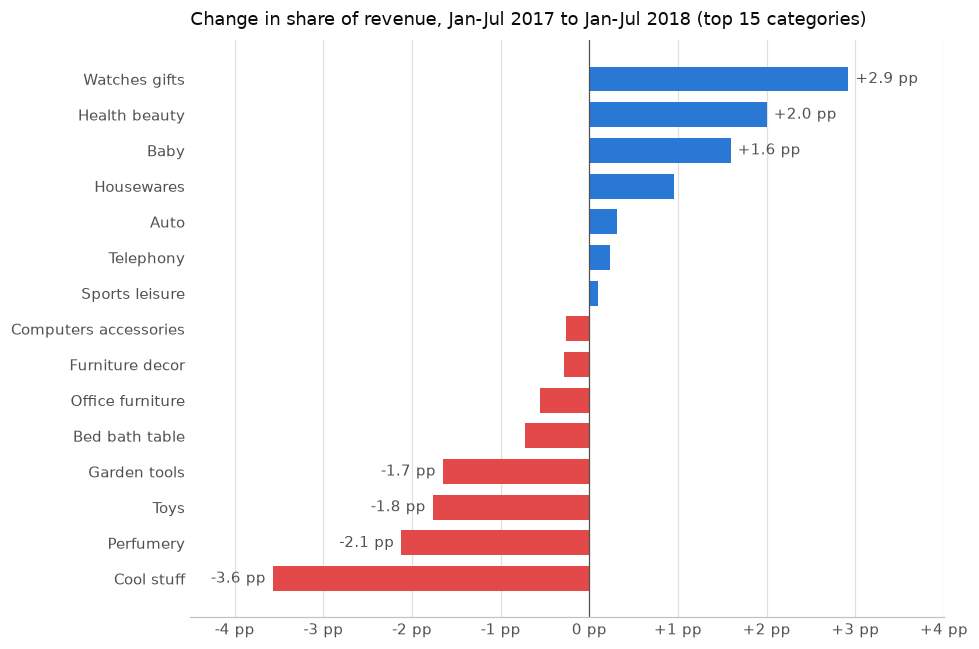

In [15]:
top_changes = share_change.loc[top_15, "change_pp"].sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_changes.index, top_changes.to_numpy(),
        color=np.where(top_changes > 0, GAIN, LOSS), height=0.7)
ax.axvline(0, color=SECONDARY_INK, linewidth=0.8)
for row, value in enumerate(top_changes):
    if abs(value) >= 1:
        ax.text(value + (0.08 if value > 0 else -0.08), row, f"{value:+.1f} pp",
                ha="left" if value > 0 else "right", va="center", color=SECONDARY_INK)

ax.set_title("Change in share of revenue, Jan-Jul 2017 to Jan-Jul 2018 (top 15 categories)")
ax.xaxis.set_major_formatter(lambda value, _: f"{value:+.0f} pp" if value else "0 pp")
ax.set_xlim(-4.5, 4)
ax.grid(axis="y", visible=False)
ax.spines["left"].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "03_category_share_change.png", dpi=150, bbox_inches="tight")
plt.show()

The next chart shows how the share of the three biggest winners (top row) and the three biggest losers (bottom row) evolved month by month.

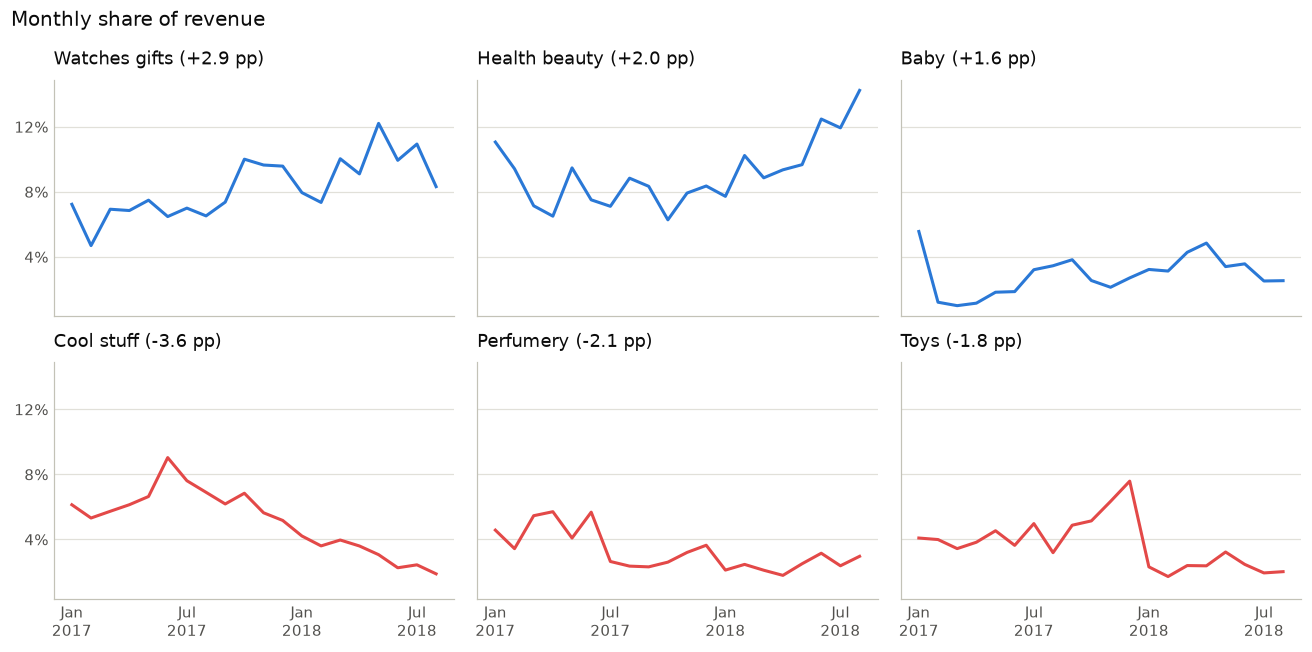

In [16]:
monthly_revenue = category_monthly.pivot(index="month", columns="category", values="revenue")
monthly_share = monthly_revenue.div(monthly_revenue.sum(axis=1), axis=0) * 100

movers = (
    list(share_change.loc[top_15, "change_pp"].nlargest(3).index)
    + list(share_change.loc[top_15, "change_pp"].nsmallest(3).index)
)
x = np.arange(len(monthly_share))
half_year_ticks = [i for i, month in enumerate(monthly_share.index) if month.month in (1, 7)]
half_year_labels = [f"{MONTHS[monthly_share.index[i].month - 1]}\n{monthly_share.index[i].year}" for i in half_year_ticks]

fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for ax, category in zip(axes.flat, movers):
    change = share_change.loc[category, "change_pp"]
    ax.plot(x, monthly_share[category].to_numpy(), color=GAIN if change > 0 else LOSS, linewidth=2)
    ax.set_title(f"{category} ({change:+.1f} pp)")
    ax.set_xticks(half_year_ticks, half_year_labels)
    ax.yaxis.set_major_locator(MultipleLocator(4))
    ax.yaxis.set_major_formatter(lambda value, _: f"{value:.0f}%")
    ax.grid(axis="x", visible=False)
fig.suptitle("Monthly share of revenue", x=0.01, ha="left", fontsize=13, color=INK)
fig.tight_layout()
plt.show()

Between the first seven months of 2017 and those of 2018, Watches gifts gained 2.9 percentage points of revenue share, Health beauty 2.0 and Baby 1.6. The biggest losers were Cool stuff (−3.6 pp), Perfumery (−2.1) and Toys (−1.8).

The monthly charts show that the changes are of different kinds:

- Cool stuff is in steady decline: its share peaked at 9.0% in June 2017 and fell to 2.4% by July 2018.
- Watches gifts and Health beauty gain share gradually, with ups and downs along the way.
- Toys behaves like a seasonal category: its share rose from 5.1% in October 2017 to 7.6% in December, consistent with Christmas shopping, and fell to 2.3% in January 2018. With a single December in the data, we cannot confirm that this repeats every year.

## 8. Saving

We save three tables for the dashboard and for the forecast in Phase 4. The monthly table by category flags August 2018 as incomplete.

In [17]:
revenue_before = categories["cumulative_pct"] - categories["revenue_pct"]
categories["abc_class"] = np.select([revenue_before < 80, revenue_before < 95], ["A", "B"], default="C")
categories["a_products_pct"] = (
    products[products["abc_class"] == "A"].groupby("category").size()
    .reindex(categories.index, fill_value=0) / categories["products"] * 100
)
categories["slow_movers"] = slow_by_category["slow_movers"].reindex(categories.index, fill_value=0)
category_summary = categories.join(share_change).reset_index()

category_monthly["is_complete_month"] = category_monthly["month"] != pd.Timestamp("2018-08-01")

outputs = {
    "product_abc.csv": products.reset_index(),
    "category_summary.csv": category_summary,
    "category_monthly.csv": category_monthly,
}
for name, table in outputs.items():
    table.to_csv(PROCESSED / name, index=False)
    print(f"{name:<24} {len(table):>8,} rows")

assert np.isclose(products["revenue"].sum(), category_monthly["revenue"].sum()), "Revenue does not match"

product_abc.csv            32,079 rows
category_summary.csv           74 rows
category_monthly.csv        1,480 rows


## Answer to business question 1

**Business question.** Which products and categories sell the most and the least?

**Analysis.** We ranked the 74 categories and the 32,079 products sold between January 2017 and August 2018 by revenue and by units, measured revenue concentration with a Pareto curve, classified each product as A, B or C, identified slow movers and compared each category's share of revenue between the first seven months of 2017 and of 2018.

**Evidence.**

- 25.9% of the products (class A) bring in 80% of revenue, while 39.8% (class C) bring in only 5%.
- 55.0% of the products sold a single unit in 20 months, and 6,707 products (20.9%) have not sold since February 22, 2018.
- 18 of the 74 categories bring in 80% of revenue, led by Health beauty, Watches gifts and Bed bath table.
- The ranking by units differs from the ranking by revenue: Bed bath table sells the most units but ranks third in revenue.
- Watches gifts (+2.9 pp), Health beauty (+2.0 pp) and Baby (+1.6 pp) gained share, while Cool stuff (−3.6 pp), Perfumery (−2.1 pp) and Toys (−1.8 pp) lost it.

**Insight.** Revenue depends on a relatively small group of products, while a long tail of rarely sold products brings in very little. Volume and revenue do not always go together, and categories are moving: some gain ground steadily, others decline, and at least one (Toys) appears to depend on the Christmas season.

**Recommendation.**

1. Treat the 8,309 class A products as the priority: they should never run out of stock, and they are the natural candidates for promotions and visibility.
2. Review the 6,707 slow movers: stop restocking them, sell them on demand, bundle them with A products or remove them from the catalog.
3. Expand the assortment in growing categories (Watches gifts, Health beauty, Baby), and investigate why Cool stuff and Perfumery are declining (prices, competition, seller issues) before cutting them.
4. Plan seasonal categories such as Toys around their peak months.

**Application to the machinery business.** This notebook can classify the business's items as soon as its sales data can be exported. We expect a few high-value items (tractors and implements) to fall in class A and many spare parts to spread across B and C, but real data has to confirm it. In practice:

- Class A items need guaranteed availability and close follow-up of stock and supplier lead times.
- Class C items and slow movers should be kept at minimal stock or ordered on demand. Machinery stock that does not move ties up a lot of money, so the six-month rule is especially useful there.
- If the business also exports the cost of each item, the ABC classification should be run on margin as well as on revenue: an expensive tractor with a thin margin may matter less than a spare part with a high one.
- Machinery sales are likely to follow the agricultural calendar, so category trends should be read against planting and harvest seasons.

**Limitations.** Olist publishes neither product names nor costs, so products are described only by category and price, and the classification uses revenue rather than margin. The period covers 20 months, and the six-month rule for slow movers is a business convention, not a statistical result.